# SPI–SPI proof of concept — p90, ordered entries, 2026-10-21

The completed 2026-10-14 extraction (283 SPIs, pyspi computation r9), recomputed with the paper's definition of $z$: every SPI contributes all $M(M-1)$ ordered off-diagonal entries. Embeddings and selected coordinates are refitted under that definition. [proof_p90_261015.ipynb](proof_p90_261015.ipynb) remains the record of the earlier symmetrised view. The figures compare ten generator classes, then four CML regimes, and finally individual SPI–SPI coordinates that distinguish pairs of classes. These embeddings illustrate organisation; they do not establish invariance to channel count or recording length.

In [1]:
from pathlib import Path
import sys, json, os
import matplotlib.pyplot as plt
import numpy as np
ROOT = Path.cwd().resolve()
while not (ROOT / 'src').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from research.proof.p90.refresh_proof_figures import (load_bank, embeddings, rank_features, plot_embedding, plot_discriminative)
BANK = Path(os.environ.get('PROOF_REFRESH_BANK', ROOT / 'data/proof/refresh-261014/features.npz'))
OUT = Path(os.environ.get('PROOF_REFRESH_OUTPUT', ROOT / 'results/proof/viewer-261021'))
bank = load_bank(BANK, expected_spis=283, contract='unified_ordered_v3')
OUT.mkdir(parents=True, exist_ok=True)
print(f"{len(bank['y'])} datasets; {len(bank['spi_order'])} SPIs; {bank['X'].shape[1]:,} coordinates ({bank['contract']})")

1080 datasets; 283 SPIs; 39,903 coordinates (unified_ordered_v3)


Feature definition (`unified_ordered_v3`): each SPI contributes its $M(M-1)$ ordered off-diagonal entries $A_{ij}$, $i\neq j$, in one common order, and $z_{ab}$ is the Pearson correlation between the vectors of SPIs $a$ and $b$. This produces $\binom{283}{2}=39\,903$ coordinates.

Both directions of every channel pair are kept. Directed SPIs therefore keep their direction, and antisymmetric SPIs now contribute: phase, PSI, PLI/wPLI and group delay vanish under symmetrisation. Values are assembled exactly from the stored v2 blocks by `mtsspi.spi_spi_contract.unified_from_feature_blocks`:
- pairs involving a directed SPI use the stored ordered-edge correlation;
- undirected pairs, whose MPIs are stored symmetric, take identical values in both views.

Each class has ten instances at every combination of $M\in\{8,16,32\}$ and $T\in\{500,1000,2000\}$. Each panel fits its own unsupervised preprocessing: retain coordinates finite in at least 95% of its datasets, median-impute missing entries, discard near-constant coordinates and centre without variance scaling. PCA provides the linear view. UMAP and t-SNE use the same first 50 PCs: UMAP has 25 neighbours, min_dist=0.25 and spectral initialisation; t-SNE has perplexity 30, PCA initialisation, automatic learning rate, early exaggeration 12 and 1,500 iterations. Both use seed 260924; their neighbourhood parameters are not numerically equivalent. Centring is a design choice, not something mathematically forced by the bounded coordinate range. No class labels enter these fits.

The three VAR models use a fixed ring with literal (self, total-neighbour) coefficients (0.70,0.20), (0.20,0.20), (0.20,0.70). Each neighbour receives half the total weight. These isolate changes in self-dependence and neighbour coupling against the same middle reference. Their spectral radii are 0.90, 0.40 and 0.90; no stability rescaling is applied. Innovation standard deviation is 0.1 and burn-in is 100 steps. This intentionally replaces the old pre-normalisation VAR weights; other generators retain their existing settings.

In [2]:
PROTOCOL = ROOT / 'research/proof/p90/configs/analysis/proof-refresh-261014.yaml'
coords = embeddings(bank, OUT, protocol_path=PROTOCOL)
ranked = rank_features(bank, OUT)

/Users/wedi0306/Code/mts-spi-study-cluster/.venv/lib/python3.12/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


Inter-class view. Colours identify classes and remain fixed in subsequent panels. Point size encodes M=8,16,32. Axis coordinates from separate fits are not directly comparable.

PCA is the primary view: its axes have linear loadings and explained variance. This makes them inspectable, not automatically identifiable with physical character; nuisance variation and redundant coordinates can dominate them. t-SNE is the nonlinear companion; UMAP remains an optional comparison below. UMAP and t-SNE axes have no intrinsic meaning; distances between clusters and cluster areas are sensitive to the method and settings. Fixed seeds do not guarantee identical layouts across platforms. Agreement is a visual robustness check, not independent validation. See the original [t-SNE](https://www.jmlr.org/papers/v9/vandermaaten08a.html) and [UMAP](https://arxiv.org/abs/1802.03426) papers, and the [initialisation comparison](https://www.nature.com/articles/s41587-020-00809-z).

The coordinate archive also stores PC1/PC2 loadings, feature indices and centring values for each panel, so the linear axes can be traced back to their SPI pairs.

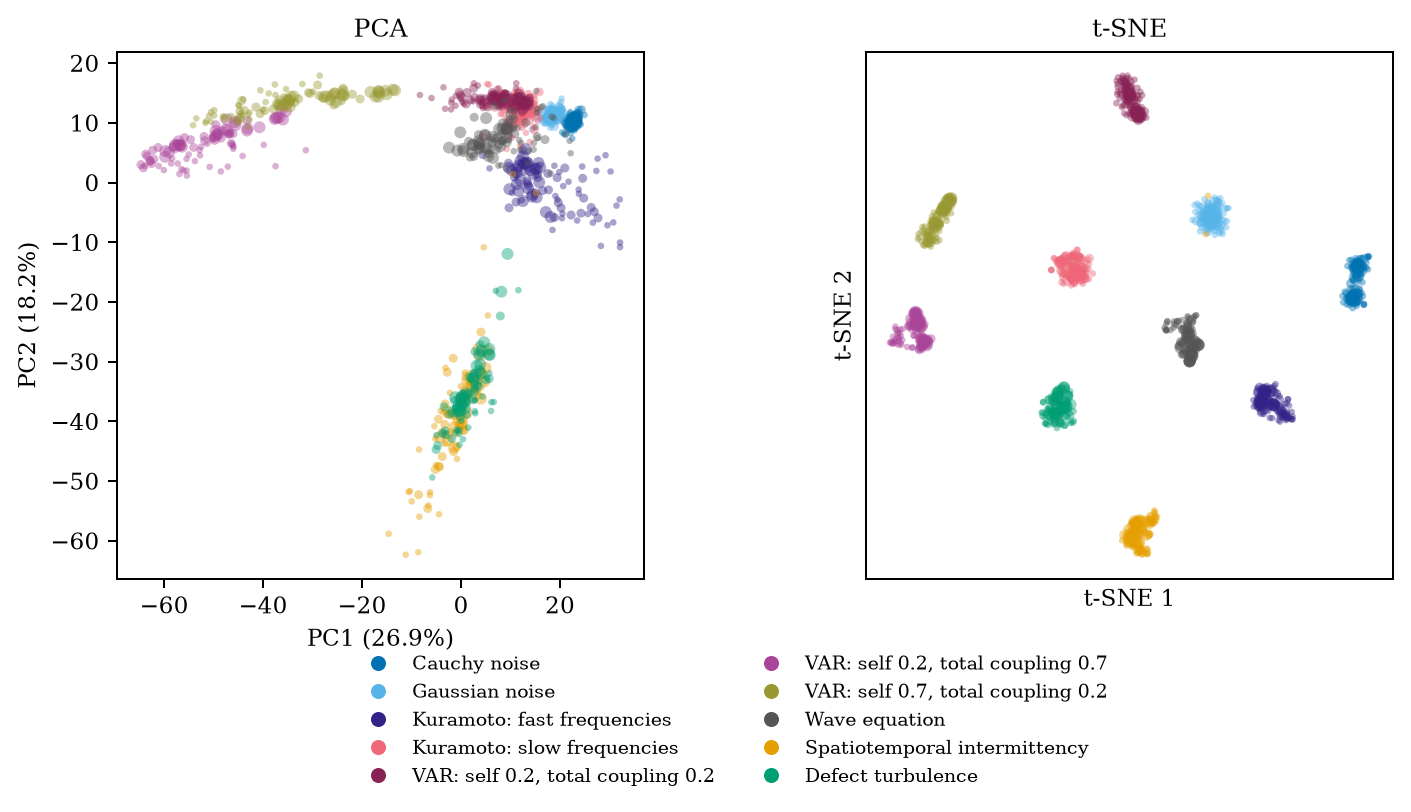

In [3]:
fig = plot_embedding(bank, coords, 'inter', OUT)
plt.show()

Within-CML view: frozen chaos, spatiotemporal intermittency, defect turbulence and fully developed turbulence. The same two bridge classes use the same datasets and colours as the inter-class view.

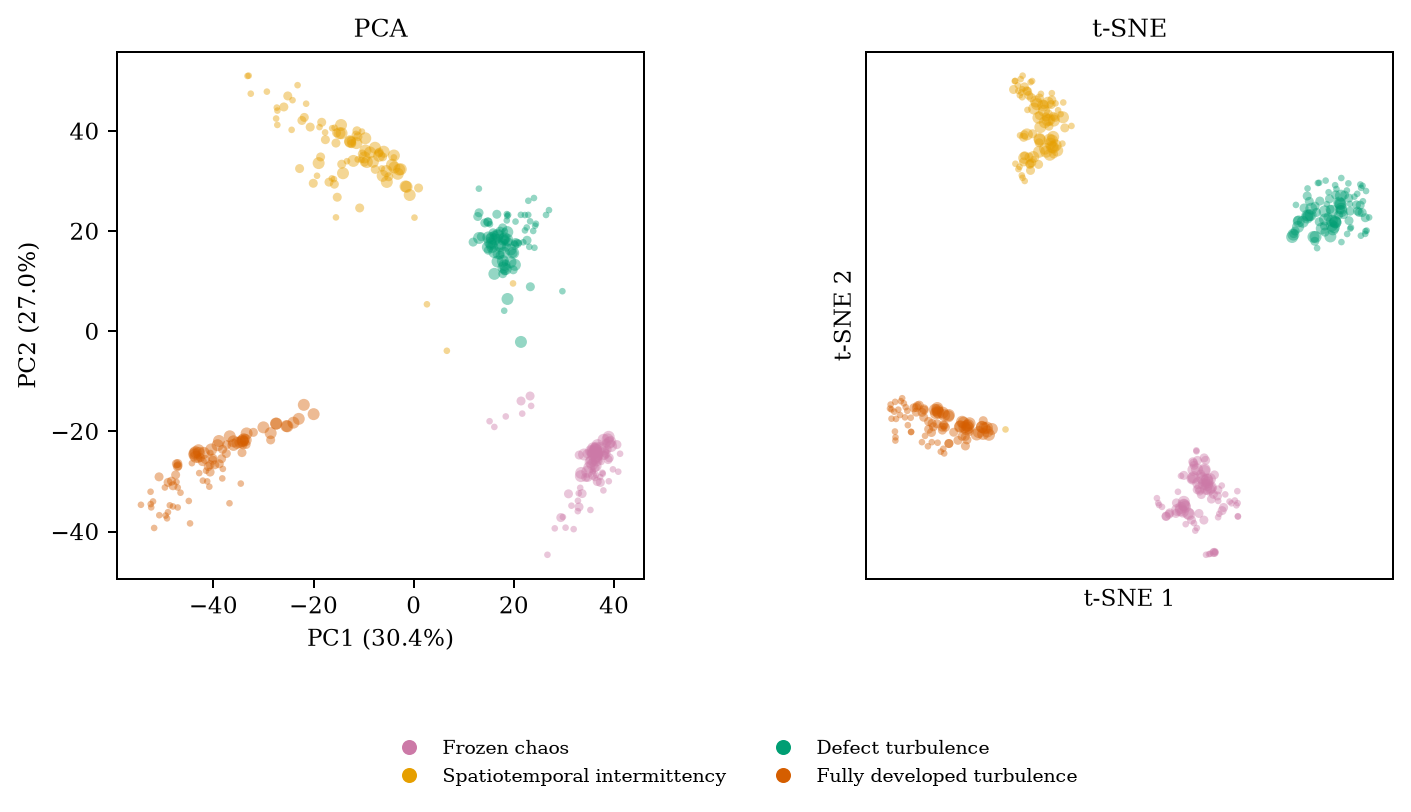

In [4]:
fig = plot_embedding(bank, coords, 'cml', OUT)
plt.show()

Discriminative coordinates. For each class pair, select the SPI pair with greatest training AUC separation using instances 0–5 across all nine M/T cells. The rainclouds display instances 6–9 only (up to 36 datasets/class; undefined coordinate values are omitted), with the training orientation fixed when calculating display AUC. Dots are datasets; density shapes are descriptive; boxes span the 25th–75th percentiles with a median line, and whiskers reach the most extreme observations within 1.5 IQR of the box. Every observation, including boxplot outliers, remains in the scatter. The left-to-right order is scatter, box-and-whisker, density. This limits feature-selection optimism within this rerun, but remains exploratory because these generator families and earlier outcomes have already been inspected. No best-feature significance claim is made.

Each panel is square and boxed. Its y-limits cover the compared classes jointly, with padding; repeated uses of one SPI coordinate share limits, while different coordinates have different limits. Read the numerical ticks when comparing panels: visible separation on a tight scale is not a large absolute change in z. All finite display observations remain visible.

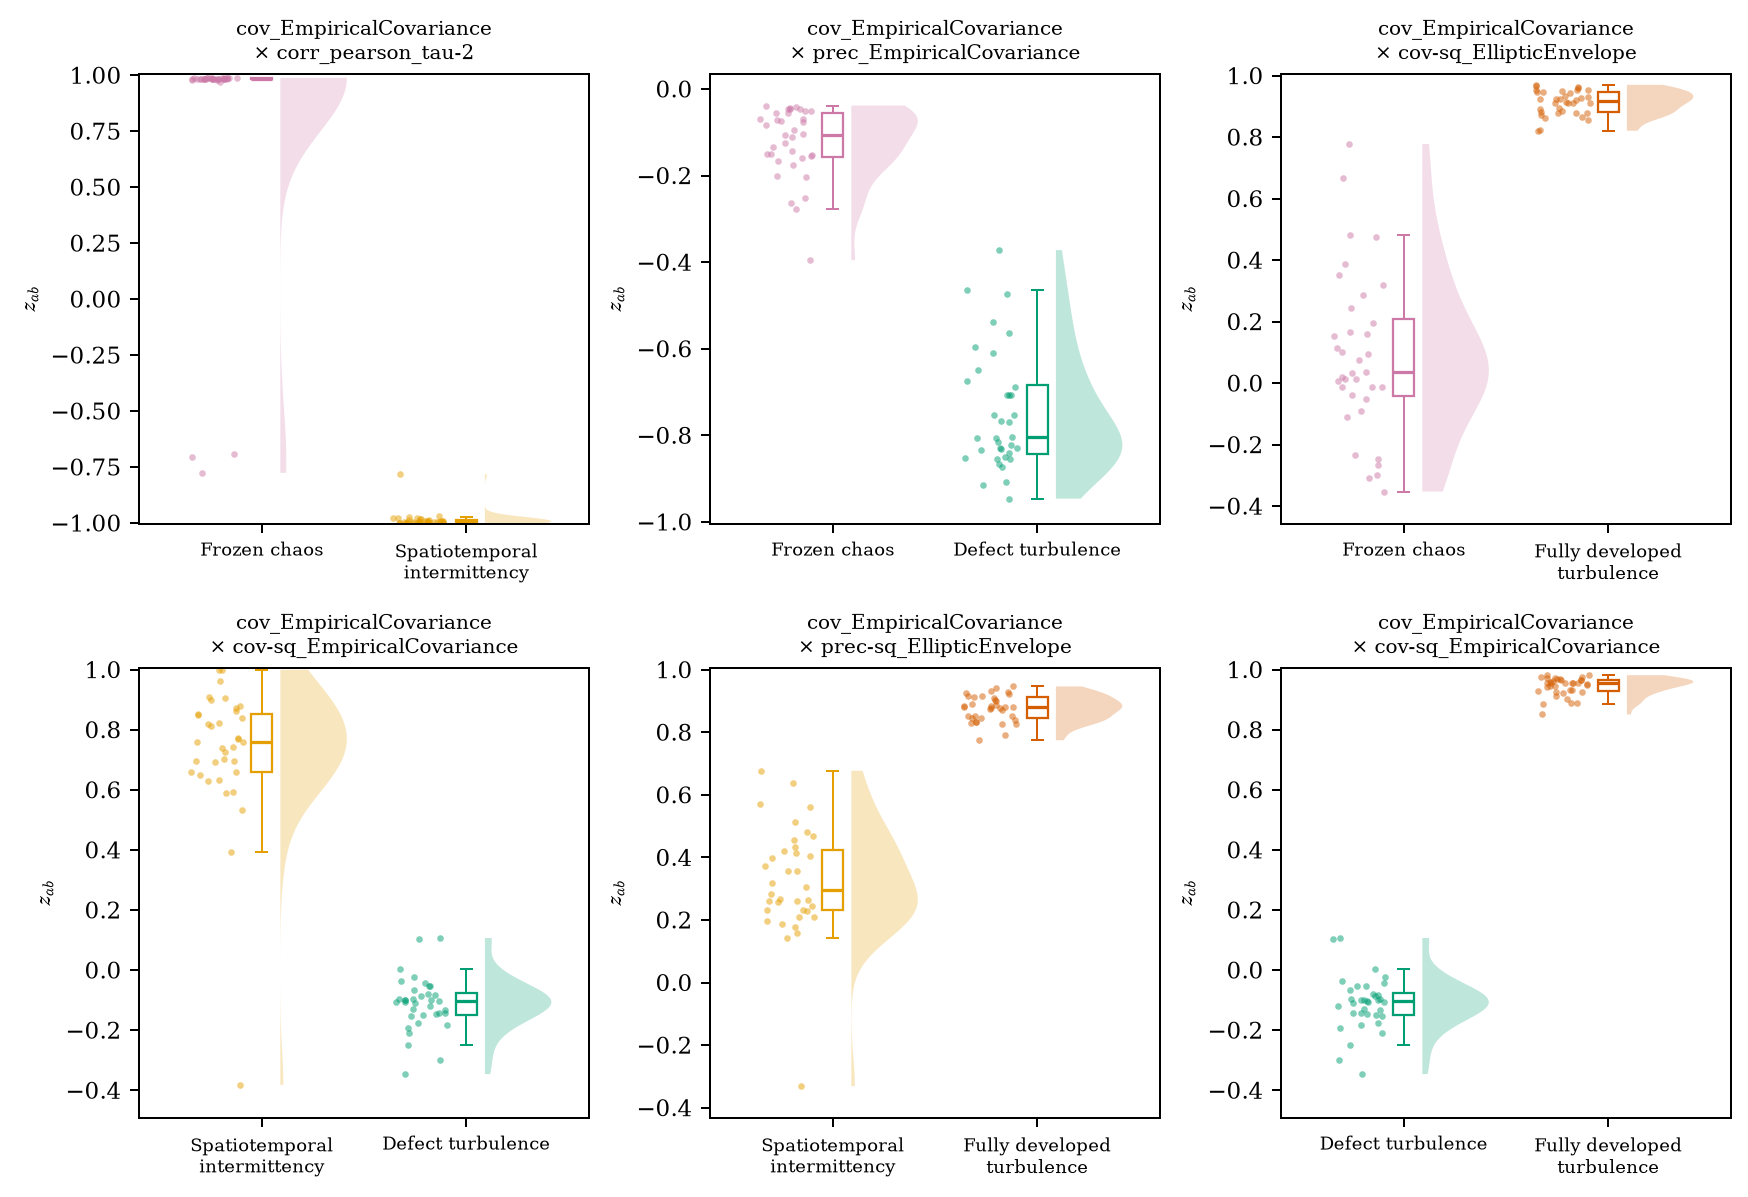

In [5]:
fig = plot_discriminative(bank, ranked, 'cml', OUT)
plt.show()

Coarse contrasts use the same selection rule for Gaussian versus Cauchy noise and all three VAR class pairs. VAR tick labels report self coupling and total neighbour coupling.

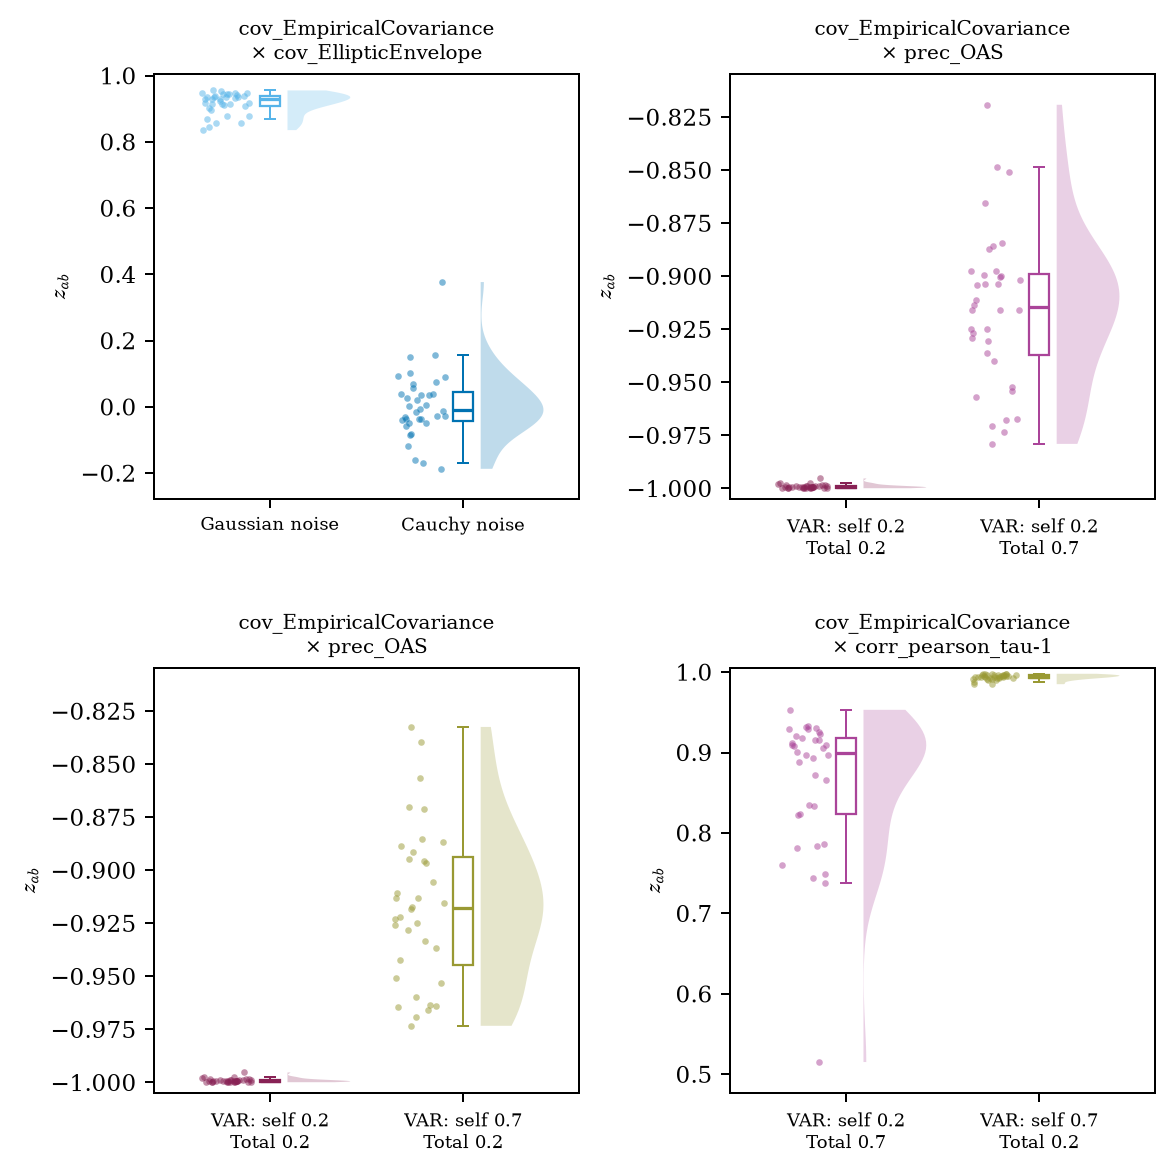

In [6]:
fig = plot_discriminative(bank, ranked, 'coarse', OUT)
plt.show()

Generation and analysis settings (unchanged; only the feature contract differs): `research/proof/p90/configs/analysis/proof-refresh-261014.yaml`. Current pyspi fixes its stochastic estimator seeds. Undefined SPI values remain masked; no historical r7 matrices enter this run. Figures are saved as SVG and PNG.

The generation YAML remains unchanged; compact raincloud layout and box-and-whisker marks are implemented in `research/proof/p90/refresh_proof_figures.py` and `src/mtsspi/figures.py`.

Optional UMAP comparison, using the same saved preprocessing and fitted coordinates. Enable the flag to display it; the main figures prioritise PCA and t-SNE.

In [7]:
SHOW_UMAP = False
if SHOW_UMAP:
    for panel in ['inter', 'cml']:
        fig = plot_embedding(bank, coords, panel, OUT, methods=['umap'])
        plt.show()

Composite figures — 2026-10-16. Each version places inter-class and within-CML embeddings above three smaller class-contrast rainclouds (2.20-inch squares). The lower row extends 0.65 inches beyond each upper side, leaving space for later annotation; panel letters are omitted. Marker **area** is proportional to $\sqrt M$ in both embeddings and rainclouds, using the same sizes and the legend inside the CML embedding. Density and box summaries weight every recording equally.

The left contrast retains the training-AUC-selected coordinate for intermittency versus defect turbulence. The middle compares fast Kuramoto with fully developed CML turbulence using the lag-10/lag-20 Pearson-profile coordinate. The right compares fast and slow Kuramoto using lag-1 Pearson versus maximum cross-correlation. For this replacement, finite coordinates were screened on instances 0–5 for separation and absolute median difference, then a simple fixed-lag versus lag-maximum comparison was chosen and frozen below. It replaces a lag-10/lag-20 contrast whose values were all close to 1. Rainclouds show instances 6–9, with identical coordinates and observations in both composites. These are exploratory illustrations, not fresh confirmatory tests.

Each raincloud has its own y-limits; numerical ticks expose the different absolute scales. Class ticks identify both groups. Boxes show median/IQR and 1.5-IQR whiskers. Colours match the embeddings. Saved formats are SVG, PDF and PNG.

In [8]:
from research.proof.p90.proof_composite import select_examples, plot_composite
COMPOSITE_PAIRS = [
    ('sti-i', 'defect-turbulence'),
    ('kuramoto_omega-fast', 'fdstc'),
    ('kuramoto_omega-fast', 'kuramoto_omega-slow'),
]
COMPOSITE_FEATURES = [
    None,
    ('corr_pearson_tau-10', 'corr_pearson_tau-20'),
    ('corr_pearson_tau-1', 'xcorr_max_sig-True'),
]
composite_selected = select_examples(bank, OUT, pairs=COMPOSITE_PAIRS,
                                     feature_pairs=COMPOSITE_FEATURES)

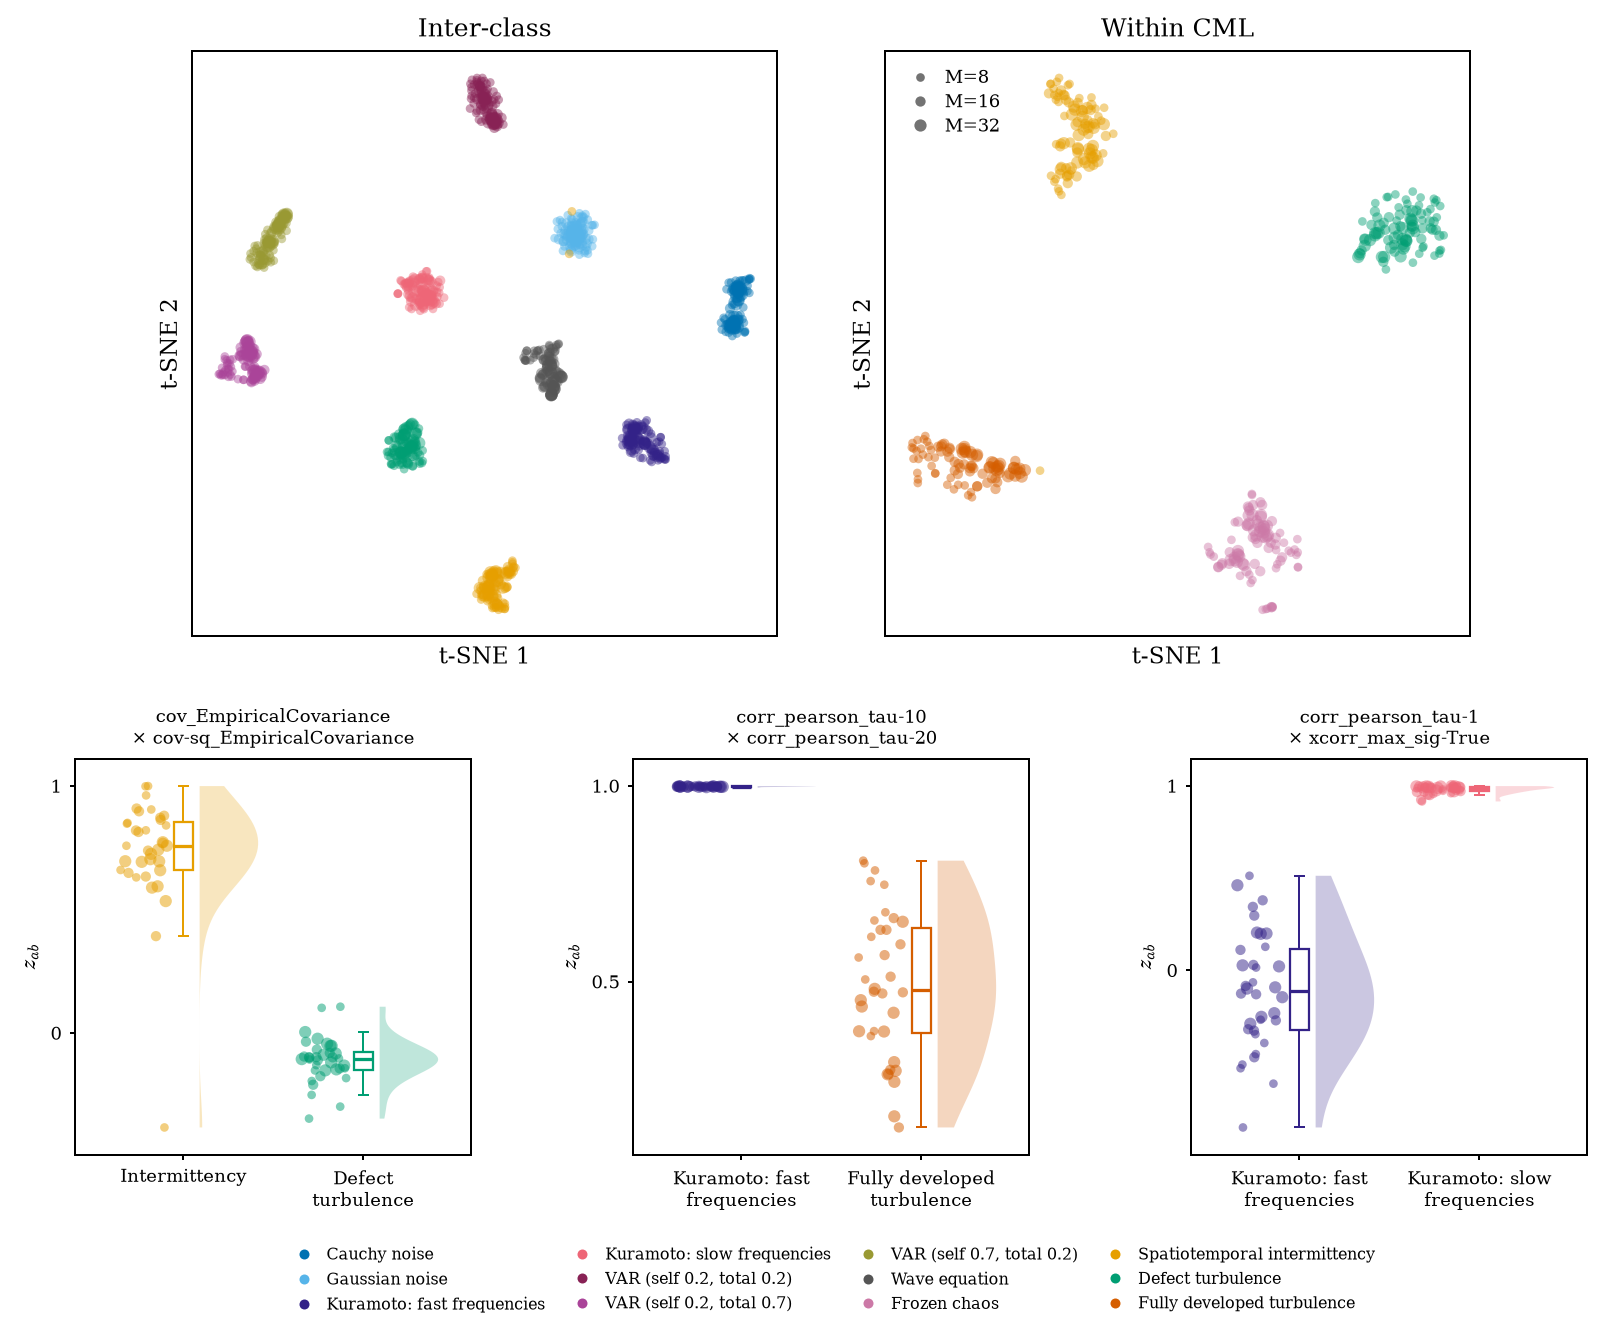

In [9]:
fig = plot_composite(bank, coords, composite_selected, 'tsne', OUT)
plt.show()

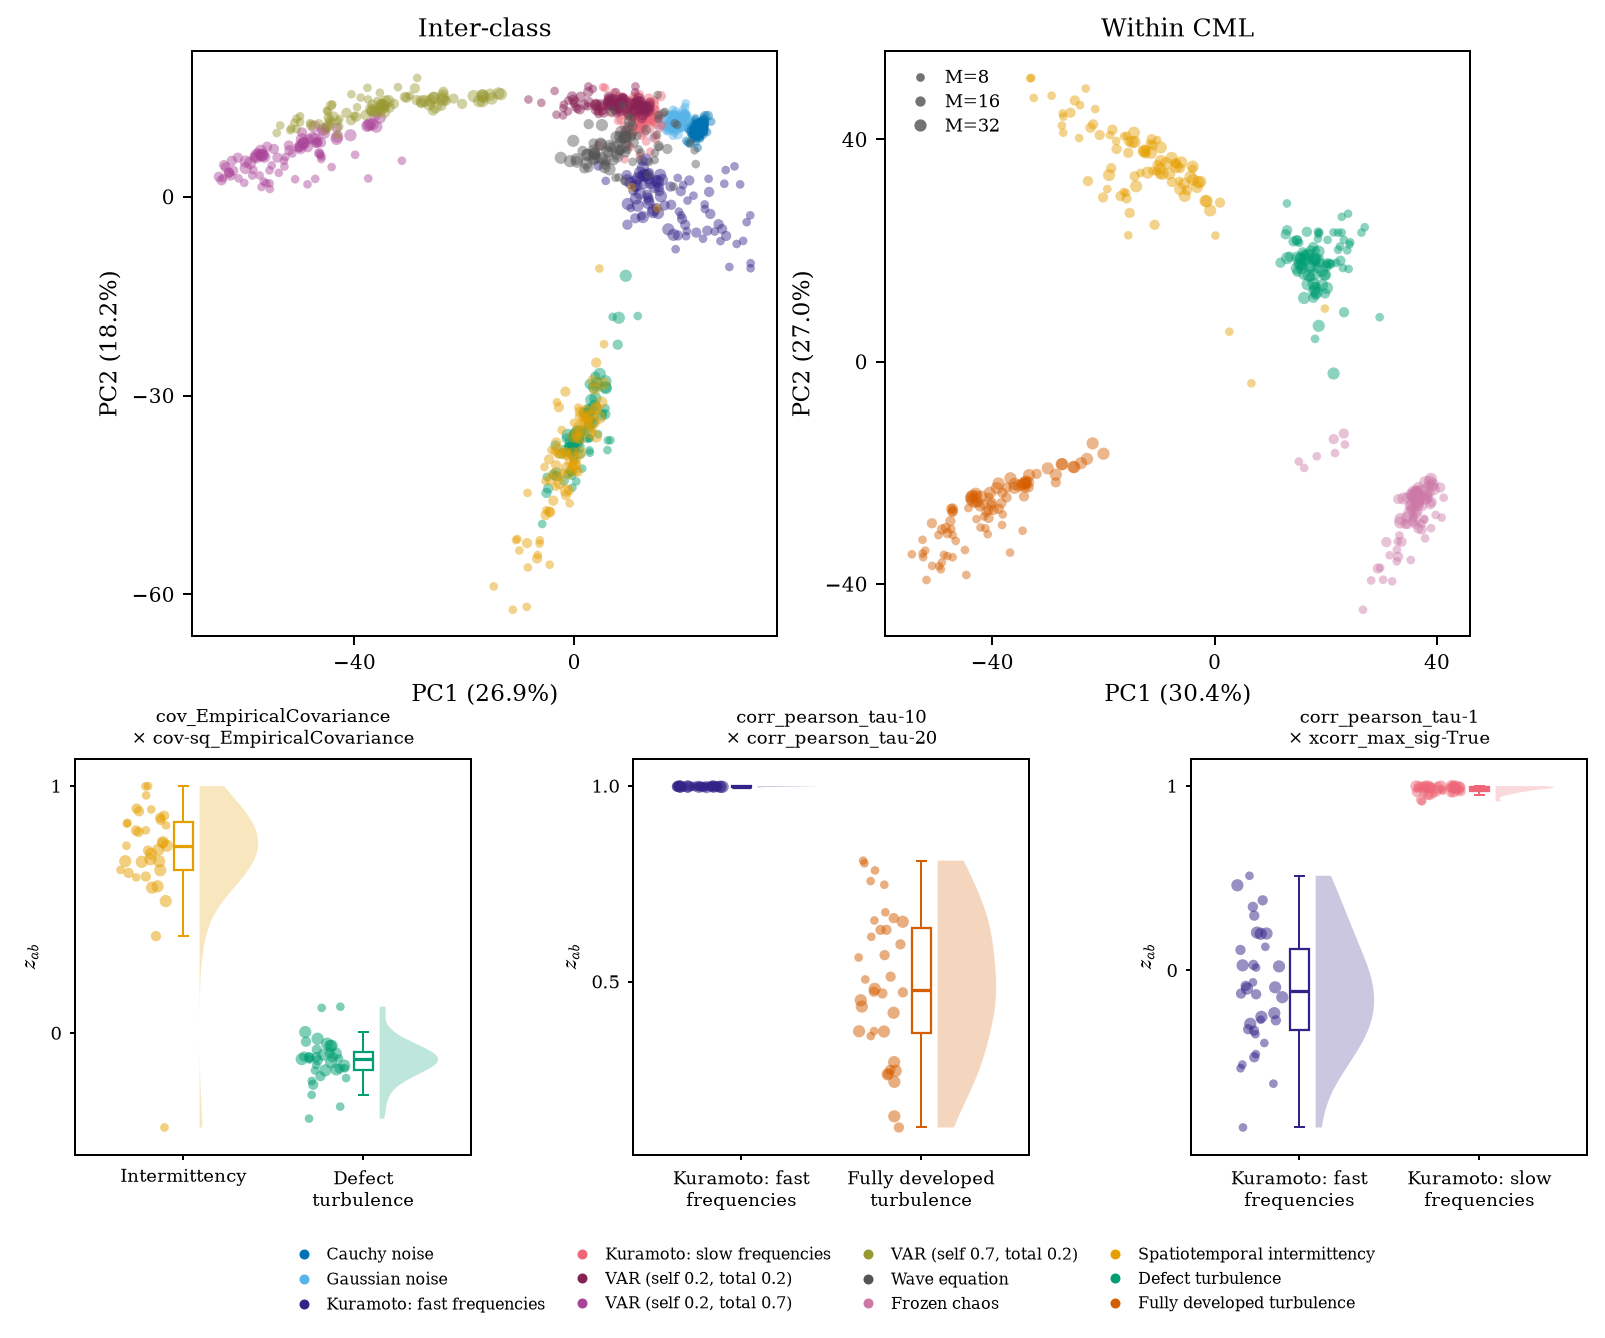

In [10]:
fig = plot_composite(bank, coords, composite_selected, 'pca', OUT)
plt.show()

The middle coordinate measures agreement between channel-pair Pearson profiles at lags 10 and 20; it does not measure individual-channel autocorrelation. The right asks whether pairs with stronger symmetric lag-1 correlation also have stronger maximum cross-correlation over $[-\lfloor T/4\rfloor,\lfloor T/4\rfloor]$. This agreement is much weaker in fast than slow Kuramoto. The pinned pyspi implementation (`c2d723f`, `statistics/basic.py`) demeans cross-correlation inputs, uses full-record normalisation, and retains lags with $|r(\ell)|>1.96/\sqrt T$ before taking the largest signed value (or returns zero if none qualify). The historical `sig-True` suffix denotes this amplitude filter, not a calibrated significance test. This is a descriptive fixed-lag versus lag-search contrast; phase, record length and the search/filter conventions can all affect it. It is not a calibrated frequency, synchrony or direction-of-influence axis.

## What the ordered entries change

Same recordings, same preprocessing, two feature definitions. The rows report, per panel:
- coordinates and SPIs retained by the 95%-finite rule;
- PCA variance.

The last table compares the training-selected coordinates with those of the symmetrised 261015 view.

**Result.** The ordered entries add 13 SPIs to each panel: the antisymmetric phase, PSI, PLI/wPLI and group-delay statistics, which contribute nothing once symmetrised. The embeddings are refitted on the larger coordinate set. Every training-selected coordinate, and every composite coordinate, is unchanged with identical held-out AUC, because each pairs undirected SPIs.

In [11]:
import pandas as pd
from research.proof.p90.refresh_proof_figures import preprocess
legacy = load_bank(BANK, expected_spis=283)
protocol_exclude = ['frozen-chaos', 'fdstc']
panels = {'inter': ~np.isin(bank['y'], protocol_exclude), 'cml': np.isin(bank['y'], ['frozen-chaos', 'sti-i', 'defect-turbulence', 'fdstc'])}
rows = []
for label, b in [('symmetrised (261015)', legacy), ('ordered (261021)', bank)]:
    for panel, mask in panels.items():
        _, keep = preprocess(b['X'][mask])
        rows.append({'contract': label, 'panel': panel, 'coordinates': int(keep.sum()), 'SPIs': len(set(b['pairs'][keep].ravel()))})
display(pd.DataFrame(rows).pivot(index='panel', columns='contract', values=['coordinates', 'SPIs']))
changed = np.nanmax(np.abs(legacy['X'] - bank['X']), axis=0) > 1e-6
print(f"{changed.sum():,} of {changed.size:,} coordinates change value; all involve a directed SPI.")
old = pd.read_csv(ROOT / 'results/proof/viewer-261015/selected-features.csv')
cols = ['class_a', 'class_b', 'spi_a', 'spi_b', 'display_auc_fixed_orientation']
display(old[cols].merge(ranked[cols], on=['class_a', 'class_b'], suffixes=(' 261015', ' 261021')).round(3))

coordinates                                  SPIs  \
contract ordered (261021) symmetrised (261015) ordered (261021)   
panel                                                             
cml                 24751                23958              233   
inter               23641                22783              228   

                               
contract symmetrised (261015)  
panel                          
cml                       220  
inter                     215

20,805 of 39,903 coordinates change value; all involve a directed SPI.


/var/folders/nq/8y70t4y10yb6nq4v5m7p_j340000gp/T/ipykernel_63160/3893880874.py:12: RuntimeWarning: All-NaN slice encountered
  changed = np.nanmax(np.abs(legacy['X'] - bank['X']), axis=0) > 1e-6


,class_a,class_b,spi_a 261015,spi_b 261015,display_auc_fixed_orientation 261015,spi_a 261021,spi_b 261021,display_auc_fixed_orientation 261021
0,frozen-chaos,sti-i,cov_EmpiricalCovariance,corr_pearson_tau-2,1.000,cov_EmpiricalCovariance,corr_pearson_tau-2,1.000
1,frozen-chaos,defect-turbulence,cov_EmpiricalCovariance,prec_EmpiricalCovariance,0.999,cov_EmpiricalCovariance,prec_EmpiricalCovariance,0.999
2,frozen-chaos,fdstc,cov_EmpiricalCovariance,cov-sq_EllipticEnvelope,1.000,cov_EmpiricalCovariance,cov-sq_EllipticEnvelope,1.000
3,sti-i,defect-turbulence,cov_EmpiricalCovariance,cov-sq_EmpiricalCovariance,0.972,cov_EmpiricalCovariance,cov-sq_EmpiricalCovariance,0.972
4,sti-i,fdstc,cov_EmpiricalCovariance,prec-sq_EllipticEnvelope,1.000,cov_EmpiricalCovariance,prec-sq_EllipticEnvelope,1.000
5,defect-turbulence,fdstc,cov_EmpiricalCovariance,cov-sq_EmpiricalCovariance,1.000,cov_EmpiricalCovariance,cov-sq_EmpiricalCovariance,1.000
6,gaussian-noise,cauchy-noise,cov_EmpiricalCovariance,cov_EllipticEnvelope,1.000,cov_EmpiricalCovariance,cov_EllipticEnvelope,1.000
7,var-self-0.2_total-0.2,var-self-0.2_total-0.7,cov_EmpiricalCovariance,prec_OAS,1.000,cov_EmpiricalCovariance,prec_OAS,1.000
8,var-self-0.2_total-0.2,var-self-0.7_total-0.2,cov_EmpiricalCovariance,prec_OAS,1.000,cov_EmpiricalCovariance,prec_OAS,1.000
9,var-self-0.2_total-0.7,var-self-0.7_total-0.2,cov_EmpiricalCovariance,corr_pearson_tau-1,1.000,cov_EmpiricalCovariance,corr_pearson_tau-1,1.000
